# 14. Prova de conceito da API

Este notebook exercita a API do repositório de endereços em execução e registra o que ela responde: a cobertura declarada, os três níveis de precisão, a qualidade com o motivo, a geocodificação reversa, o desempenho das rotas e a contabilização de uso. A última seção mede, sobre 20.000 endereços do BHMap, quanto cada sinal da resposta antecipa o erro e compara com o geocodebr.

O notebook exige os serviços no ar (`docker compose up -d --build` e `python scripts/load_cnefe_to_postgis.py`) e roda com `run_pipeline.py --com-api`. A carga vem do mestre do [NB05](05_acuracia_gci.ipynb). As saídas registram uma execução sobre uma carga com 605.811 endereços. A carga atual tem 590.615, e o teste independente da calibração, com amostras separadas por bloco espacial, está no [NB17](17_teste_operacional_independente.ipynb).

In [1]:
import sys, warnings
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
sys.path.insert(0, str(Path.cwd().parent))
from src import config


In [2]:
import json
import time
import urllib.error
import urllib.request

BASE = 'http://localhost:8000'

def chamar(rota, corpo=None, metodo=None):
    """Chamada HTTP simples. Devolve (status, corpo, latencia_ms)."""
    dados = json.dumps(corpo).encode() if corpo is not None else None
    pedido = urllib.request.Request(
        BASE + rota, data=dados, method=metodo or ('POST' if dados else 'GET'),
        headers={'Content-Type': 'application/json'})
    inicio = time.perf_counter()
    try:
        with urllib.request.urlopen(pedido, timeout=30) as resposta:
            corpo_resposta = json.loads(resposta.read())
            status = resposta.status
    except urllib.error.HTTPError as erro:
        corpo_resposta = json.loads(erro.read() or b'{}')
        status = erro.code
    except Exception as erro:
        return None, {'erro': str(erro)}, None
    return status, corpo_resposta, (time.perf_counter() - inicio) * 1000

status, saude, _ = chamar('/health')
if status is None:
    print('API indisponivel. Suba os servicos com: docker compose up -d --build')
else:
    print(f"Servico: {saude['status']} | versao {saude['versao']}")
    print(f"Enderecos carregados: {saude['enderecos']:,} em {saude['municipios']} municipio(s)")

Servico: ok | versao 2.0.0
Enderecos carregados: 605,811 em 1 municipio(s)


## 1. Cobertura do Repositório

Antes de consultar um geocodificador, o consumidor precisa saber o que ele contém. A rota `/cobertura` declara município, unidade federativa, fonte e volume, o que torna o alcance do serviço verificável em vez de presumido.


In [3]:
# Cobertura declarada pelo proprio servico
_, cobertura, _ = chamar('/cobertura')
tabela_cobertura = pd.DataFrame(cobertura)
display(tabela_cobertura)
print(f"\nTotal de enderecos geocodificaveis: {tabela_cobertura['enderecos'].sum():,}")
print(f"Total de unidades representadas:     {tabela_cobertura['unidades'].sum():,}")

,codigo_municipio,municipio,uf,fonte,enderecos,unidades
0,3106200,Belo Horizonte,MG,CNEFE_2022,605811,1172902



Total de enderecos geocodificaveis: 605,811
Total de unidades representadas:     1,172,902


O repositório carregado cobre um município, Belo Horizonte, com 605.811 endereços geocodificáveis que representam 1.172.902 unidades. A diferença entre os dois números é a consolidação: as unidades de um mesmo edifício compartilham um endereço e uma coordenada, e ficam registradas na tabela de unidades.

O esquema é nacional por construção, com chave de município e unidade federativa em cada endereço, e a carga é parametrizada por município. A cobertura efetiva, porém, é a de Belo Horizonte, e o serviço declara isso na própria resposta em vez de deixar o consumidor supor alcance nacional.


## 2. Os três níveis de precisão

O contrato de resposta diz até onde a consulta casou. Um geocodificador que devolve coordenada para tudo, sem qualificar o casamento, transfere ao usuário um erro que ele não tem como perceber, como mostra a comparação da Seção 7.

As consultas abaixo exercitam os três níveis, incluindo o endereço escrito por extenso com bairro e cidade e um número que não existe no logradouro.

In [4]:
# Consultas que exercitam os tres niveis de precisao
casos = [
    ('Avenida Afonso Pena, 1212', 'numero que existe'),
    ('av. afonso pena 1212', 'mesma consulta com abreviacao e sem virgula'),
    ('Rua da Bahia, 1000, Centro, Belo Horizonte', 'endereco completo, com bairro e cidade'),
    ('Avenida Afonso Pena, 999999', 'numero que nao existe no logradouro'),
    ('Praca Sete de Setembro', 'consulta sem numero'),
]

linhas = []
for consulta, situacao in casos:
    status, corpo, latencia = chamar('/geocode', {'endereco': consulta, 'limite': 1})
    if status != 200:
        linhas.append({'Consulta': consulta, 'Situacao': situacao, 'Resposta': f'HTTP {status}'})
        continue
    melhor = corpo['candidatos'][0]
    linhas.append({
        'Consulta': consulta,
        'Situacao': situacao,
        'Encontrado': melhor['endereco_encontrado'],
        'Nivel': melhor['nivel_precisao'],
        'Confianca posicional': melhor['qualidade']['confianca_posicional'],
        'Incerteza identidade': melhor['qualidade']['incerteza_identidade'],
        'Erro mediano da classe (m)': melhor['qualidade']['calibracao']['erro_mediano_m'],
        'CE90 da classe (m)': melhor['qualidade']['calibracao']['erro_ce90_m'],
        'GCI': melhor['qualidade']['gci_empirico'],
        'Plus Code': melhor['plus_code'],
        'ms': round(latencia, 1),
    })

resultado_consultas = pd.DataFrame(linhas)
display(resultado_consultas)
resultado_consultas.to_csv(config.TAB_DIR / 'nb14_consultas_api.csv', index=False)

,Consulta,Situacao,Encontrado,Nivel,Confianca posicional,Incerteza identidade,Erro mediano da classe (m),CE90 da classe (m),GCI,Plus Code,ms
0,"Avenida Afonso Pena, 1212",numero que existe,"AVENIDA AFONSO PENA, 1212",numero_exato,alta,baixa,8.20,20.98,0.761,58GR33G7+JG,44.7
1,av. afonso pena 1212,mesma consulta com abreviacao e sem virgula,"AVENIDA AFONSO PENA, 1212",numero_exato,alta,baixa,8.20,20.98,0.761,58GR33G7+JG,17.3
2,"Rua da Bahia, 1000, Centro, Belo Horizonte","endereco completo, com bairro e cidade","RUA DA BAHIA, 1000",numero_exato,alta,baixa,8.20,20.98,0.601,58GR33G7+G5,38.4
3,"Avenida Afonso Pena, 999999",numero que nao existe no logradouro,"AVENIDA AFONSO PENA, 4444",logradouro,baixa,baixa,287.73,12736.67,0.861,58GR332H+HR,10.1
4,Praca Sete de Setembro,consulta sem numero,"RUA SETE DE SETEMBRO, 305",logradouro,baixa,moderada,287.73,12736.67,0.108,58GQ3X3X+X8,10.5


Os cinco casos se comportam como esperado. O endereço com número existente casa no nível `numero_exato`, e a mesma consulta abreviada e sem vírgula chega ao mesmo resultado, porque a forma canônica é aplicada à consulta antes da busca. O endereço completo, com bairro e cidade, é decomposto sem contaminar o termo de busca. O número inexistente é resolvido no logradouro certo e devolvido no nível de logradouro, porque a diferença de numeração passa do limite aceito. A consulta sem número também volta no nível de logradouro.

Os dois últimos casos separam um serviço utilizável de um enganoso: em ambos há coordenada de retorno, e em ambos a resposta diz que não é um casamento exato.

## 3. Qualidade com Motivo

A classe de confiança não descreve apenas o ponto guardado no repositório, e sim a resposta àquela consulta. Um ponto de ótima qualidade devolvido para um número que não existe não é uma resposta de alta confiança. O serviço explicita o que determinou a classe.


In [5]:
# A resposta explica por que a confianca foi rebaixada
for consulta in ['Avenida Afonso Pena, 1212', 'Avenida Afonso Pena, 999999',
                 'Praca Sete de Setembro']:
    _, corpo, _ = chamar('/geocode', {'endereco': consulta, 'limite': 1})
    melhor = corpo['candidatos'][0]
    print(f"{consulta}")
    print(f"  -> {melhor['endereco_encontrado']}  ({melhor['latitude']:.6f}, {melhor['longitude']:.6f})")
    print(f"     nivel: {melhor['nivel_precisao']}"
          f" | confianca posicional: {melhor['qualidade']['confianca_posicional']}"
          f" | incerteza de identidade: {melhor['qualidade']['incerteza_identidade']}")
    cal = melhor['qualidade']['calibracao']
    if cal['status'] == 'calibrada':
        n_fmt = f"{cal['n_amostra']:,}".replace(',', '.')   # milhar no padrao pt-BR
        print(f"     calibracao: {cal['status']} ({cal['base']}, n={n_fmt}); "
              f"mediana {cal['erro_mediano_m']} m, CE90 {cal['erro_ce90_m']} m, "
              f"acima de 100 m {cal['acima_de_100_m_pct']}%")
    else:
        print(f"     calibracao: {cal['status']} - sem verdade de campo neste municipio")
    print(f"     motivo: {melhor['qualidade']['motivo']}")
    print()

Avenida Afonso Pena, 1212
  -> AVENIDA AFONSO PENA, 1212  (-19.923425, -43.936167)
     nivel: numero_exato | confianca posicional: alta | incerteza de identidade: baixa
     calibracao: calibrada (nivel+confianca, n=16.217); mediana 8.2 m, CE90 20.98 m, acima de 100 m 1.83%
     motivo: casamento exato de logradouro e número; nesta classe, o erro mediano medido foi de 8.2 m e o CE90 de 21.0 m

Avenida Afonso Pena, 999999
  -> AVENIDA AFONSO PENA, 4444  (-19.948602, -43.920463)
     nivel: logradouro | confianca posicional: baixa | incerteza de identidade: baixa
     calibracao: calibrada (nivel+confianca, n=1.004); mediana 287.73 m, CE90 12736.67 m, acima de 100 m 67.33%
     motivo: a resposta identifica o logradouro, não o imóvel; nesta classe, o erro mediano medido foi de 287.7 m e o CE90 de 12736.7 m

Praca Sete de Setembro
  -> RUA SETE DE SETEMBRO, 305  (-19.945125, -44.001726)
     nivel: logradouro | confianca posicional: baixa | incerteza de identidade: moderada
     calibrac

O rebaixamento da confiança tem quatro origens declaradas: o nível de precisão do casamento, a similaridade do logradouro, a dispersão entre as coordenadas consolidadas naquele endereço e a partilha da coordenada por muitos registros da fonte, medida pelo CDI. Nesse último caso, a resposta informa que a coordenada identifica o edifício, e não a unidade consultada.

### 3.1 Resposta completa

O corpo devolvido ao consumidor traz a coordenada, o Plus Code, a procedência, o nível de precisão e o bloco de qualidade.

In [6]:
# Resposta completa de uma consulta, como o consumidor a recebe
_, corpo, _ = chamar('/geocode', {'endereco': 'Avenida Afonso Pena, 1212', 'limite': 1})
print(json.dumps(corpo['candidatos'][0], indent=2, ensure_ascii=False))

{
  "endereco_encontrado": "AVENIDA AFONSO PENA, 1212",
  "logradouro": "AVENIDA AFONSO PENA",
  "numero": "1212",
  "bairro": "Centro",
  "cep": "30130003",
  "municipio": "Belo Horizonte",
  "uf": "MG",
  "fonte": "CNEFE_2022",
  "latitude": -19.923425,
  "longitude": -43.936167,
  "plus_code": "58GR33G7+JG",
  "nivel_precisao": "numero_exato",
  "similaridade_logradouro": 1.0,
  "diferenca_numero": null,
  "qualidade": {
    "confianca_posicional": "alta",
    "incerteza_identidade": "baixa",
    "calibracao": {
      "status": "calibrada",
      "referencia": "BHMap (Prodabel/PBH), 19.924 endereços medidos",
      "base": "nivel+confianca",
      "n_amostra": 16217,
      "erro_mediano_m": 8.2,
      "erro_ce90_m": 20.98,
      "acima_de_30_m_pct": 5.77,
      "acima_de_100_m_pct": 1.83
    },
    "motivo": "casamento exato de logradouro e número; nesta classe, o erro mediano medido foi de 8.2 m e o CE90 de 21.0 m",
    "gci_empirico": 0.761,
    "lci": 1.0,
    "mci": 0.761,
    "

## 4. Geocodificação Reversa

Dada uma coordenada, o serviço devolve o endereço mais próximo dentro de um raio, com a distância medida. Na reversa a coordenada é o dado de entrada, então é a distância que gradua a resposta.


In [7]:
# Geocodificacao reversa a partir de uma coordenada na Praca Sete
_, reversa, latencia_rev = chamar('/reverse', {'latitude': -19.9191, 'longitude': -43.9386})
print(json.dumps(reversa, indent=2, ensure_ascii=False))
print(f"\nLatencia: {latencia_rev:.1f} ms")

{
  "endereco_encontrado": "AVENIDA AFONSO PENA, 705",
  "logradouro": "AVENIDA AFONSO PENA",
  "numero": "705",
  "bairro": "Centro",
  "cep": "30130002",
  "municipio": "Belo Horizonte",
  "uf": "MG",
  "fonte": "CNEFE_2022",
  "latitude": -19.919296,
  "longitude": -43.938677,
  "plus_code": "58GR33J6+7G",
  "nivel_precisao": "logradouro",
  "similaridade_logradouro": 1.0,
  "diferenca_numero": null,
  "qualidade": {
    "confianca_posicional": "baixa",
    "incerteza_identidade": "baixa",
    "calibracao": {
      "status": "calibrada",
      "referencia": "BHMap (Prodabel/PBH), 19.924 endereços medidos",
      "base": "nivel+confianca",
      "n_amostra": 1004,
      "erro_mediano_m": 287.73,
      "erro_ce90_m": 12736.67,
      "acima_de_30_m_pct": 85.76,
      "acima_de_100_m_pct": 67.33
    },
    "motivo": "o endereço mais próximo está a 23 m da coordenada consultada; a resposta identifica o logradouro, não o imóvel; nesta classe, o erro mediano medido foi de 287.7 m e o CE90 

A coordenada consultada, na Praça Sete, retorna o endereço mais próximo a 23 m. Como a distância ultrapassa o limite de 20 m adotado para identificar o imóvel, o serviço rebaixa a resposta ao nível de logradouro e informa a distância no motivo, em vez de apresentar o endereço como exato.


## 5. Desempenho

A prova de conceito precisa responder em tempo compatível com uso interativo e com processamento em lote, que é o caso de uso típico em pesquisa: geocodificar uma base inteira de registros de saúde ou de segurança pública.


,Rota,Chamadas,Mediana (ms),p90 (ms),Maxima (ms)
0,/geocode,20,16.5,26.4,32.3
1,/reverse,20,18.7,39.0,76.4
2,/cobertura,20,180.7,202.8,237.6


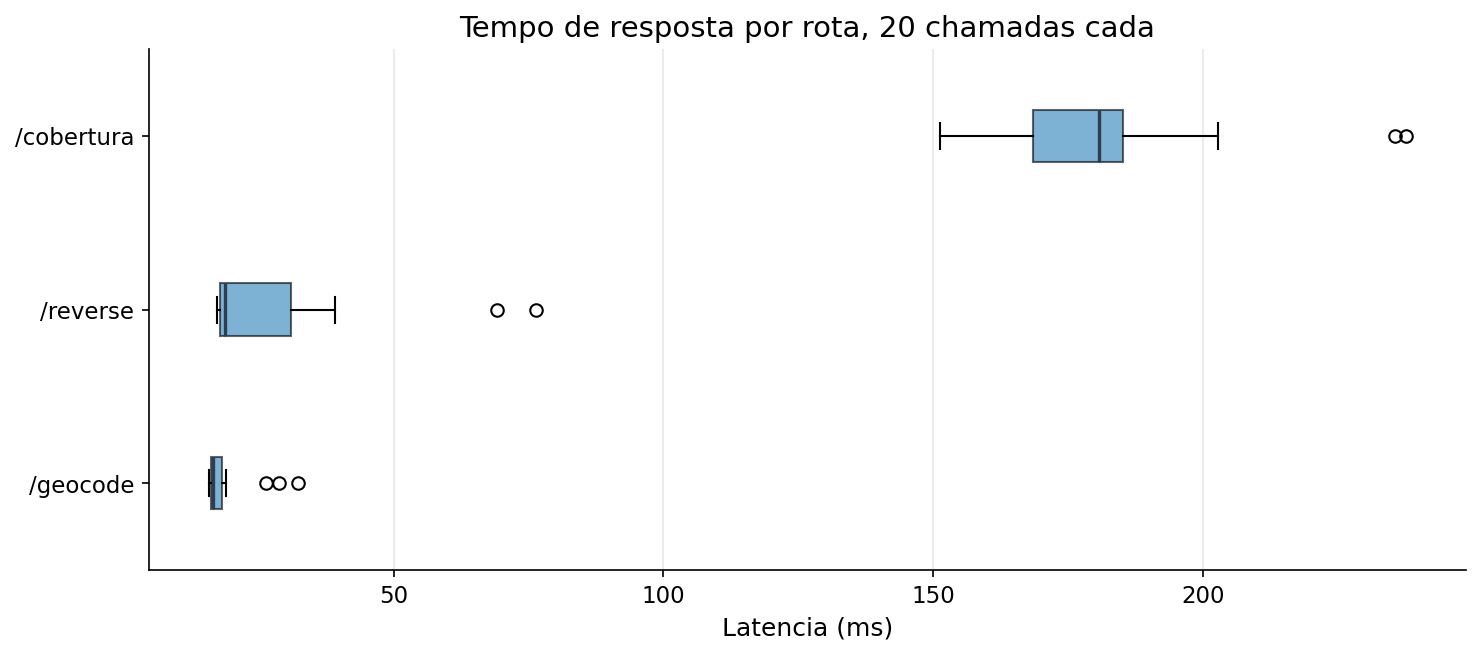

In [8]:
# Latencia das rotas, 20 chamadas cada
import statistics

medicoes = {}
for rota, corpo in [('/geocode', {'endereco': 'Rua dos Guajajaras, 1000'}),
                    ('/reverse', {'latitude': -19.9191, 'longitude': -43.9386}),
                    ('/cobertura', None)]:
    tempos = []
    for _ in range(20):
        _, _, ms = chamar(rota, corpo)
        if ms is not None:
            tempos.append(ms)
    medicoes[rota] = tempos

desempenho = pd.DataFrame([
    {'Rota': rota, 'Chamadas': len(t),
     'Mediana (ms)': round(statistics.median(t), 1),
     'p90 (ms)': round(sorted(t)[int(len(t) * 0.9) - 1], 1),
     'Maxima (ms)': round(max(t), 1)}
    for rota, t in medicoes.items() if t
])
display(desempenho)
desempenho.to_csv(config.TAB_DIR / 'nb14_desempenho_api.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([medicoes[r] for r in medicoes if medicoes[r]],
           labels=[r for r in medicoes if medicoes[r]], vert=False, patch_artist=True,
           boxprops=dict(facecolor='#2980b9', alpha=0.6),
           medianprops=dict(color='#2c3e50', linewidth=1.6))
ax.set_xlabel('Latencia (ms)')
ax.set_title('Tempo de resposta por rota, 20 chamadas cada')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig(config.FIG_DIR / 'nb14_latencia_api.png', dpi=200, bbox_inches='tight')
plt.show()

As rotas `/geocode` e `/reverse` respondem com medianas de 16,5 ms e 18,7 ms, e P90 de 26,4 ms e 39,0 ms. A rota `/cobertura`, que agrega a carga inteira, leva 180,7 ms. Os tempos permitem tanto a consulta interativa quanto a geocodificação em lote de bases grandes.

### 5.1 Por que a consulta é rápida

Três formulações da mesma busca textual são comparadas pelo plano de execução do PostgreSQL.

In [9]:
# Por que a consulta e rapida: os tres desenhos possiveis da busca textual
from sqlalchemy import create_engine, text
from src.env import database_url

engine = create_engine(database_url())
TERMO = 'AVENIDA AFONSO PENA'

def plano(sql):
    with engine.begin() as conexao:
        conexao.execute(text('SET LOCAL pg_trgm.similarity_threshold = 0.30'))
        linhas = conexao.execute(text('EXPLAIN (ANALYZE, COSTS OFF) ' + sql),
                                 {'t': TERMO}).fetchall()
    texto = chr(10).join(l[0] for l in linhas)
    tempo = float(texto.split('Execution Time:')[1].split('ms')[0])
    return tempo, ('Seq Scan' in texto), texto

desenhos = {
    'similarity() sobre a tabela de enderecos':
        "SELECT id_endereco FROM endereco WHERE similarity(logradouro, :t) >= 0.30 "
        "ORDER BY similarity(logradouro, :t) DESC LIMIT 5",
    'operador % sobre a tabela de enderecos':
        "SELECT id_endereco FROM endereco WHERE logradouro % :t "
        "ORDER BY similarity(logradouro, :t) DESC LIMIT 5",
    'operador % sobre a dimensao de logradouros (adotado)':
        "WITH ruas AS (SELECT logradouro FROM logradouro_busca WHERE logradouro % :t "
        "ORDER BY similarity(logradouro, :t) DESC LIMIT 5) "
        "SELECT e.id_endereco FROM ruas r JOIN endereco e ON e.logradouro = r.logradouro LIMIT 5",
}

linhas_indice = []
for rotulo, sql in desenhos.items():
    tempo, varredura, texto = plano(sql)
    linhas_indice.append({'Desenho da consulta': rotulo, 'Tempo (ms)': round(tempo, 1),
                          'Varredura sequencial': varredura})
    if 'adotado' in rotulo:
        plano_adotado = texto

comparacao_indice = pd.DataFrame(linhas_indice)
display(comparacao_indice)
comparacao_indice.to_csv(config.TAB_DIR / 'nb14_uso_do_indice.csv', index=False)
base = comparacao_indice['Tempo (ms)'].iloc[0]
print(f"Ganho do desenho adotado sobre o predicado por funcao: "
      f"{base / comparacao_indice['Tempo (ms)'].iloc[-1]:.0f}x")
print()
print('Plano do desenho adotado:')
print(plano_adotado)

,Desenho da consulta,Tempo (ms),Varredura sequencial
0,similarity() sobre a tabela de enderecos,796.7,True
1,operador % sobre a tabela de enderecos,138.8,False
2,operador % sobre a dimensao de logradouros (ad...,2.3,False


Ganho do desenho adotado sobre o predicado por funcao: 346x

Plano do desenho adotado:
Limit (actual time=2.247..2.254 rows=5 loops=1)
  ->  Nested Loop (actual time=2.246..2.252 rows=5 loops=1)
        ->  Limit (actual time=2.164..2.165 rows=1 loops=1)
              ->  Sort (actual time=2.163..2.163 rows=1 loops=1)
                    Sort Key: (similarity((logradouro_busca.logradouro)::text, 'AVENIDA AFONSO PENA'::text)) DESC
                    Sort Method: top-N heapsort  Memory: 25kB
                    ->  Bitmap Heap Scan on logradouro_busca (actual time=0.434..2.146 rows=58 loops=1)
                          Recheck Cond: ((logradouro)::text % 'AVENIDA AFONSO PENA'::text)
                          Rows Removed by Index Recheck: 358
                          Heap Blocks: exact=133
                          ->  Bitmap Index Scan on idx_logradouro_busca_trgm (actual time=0.405..0.405 rows=416 loops=1)
                                Index Cond: ((logradouro)::text % 'AVENIDA AFO

A comparação mostra três decisões de projeto encadeadas.

A primeira é o predicado. Escrever a busca como `similarity(logradouro, termo) >= 0,30` parece equivalente a usar o operador `%`, mas só o operador aciona o índice de trigrama. Com o predicado por função, o PostgreSQL varre sequencialmente a tabela inteira de endereços.

A segunda é a granularidade da busca. O usuário procura por nome de via, e as vias distintas são duas ordens de grandeza menos numerosas que os endereços, 12.576 contra 605.811 nesta carga. Pesquisar o trigrama na dimensão de logradouros e só então recuperar os números da via escolhida evita calcular a similaridade para cada endereço da mesma rua.

A terceira é o custo declarado do operador. Numa tabela pequena, o planejador subestima o custo da similaridade e prefere a varredura sequencial mesmo com o índice disponível. Declarar o custo real do operador corrige a escolha.

Nesta medição, a busca cai de 796,7 ms para 2,3 ms, um ganho de 346 vezes. No serviço, a consulta passa de cerca de 900 ms para cerca de 10 ms, e geocodificar uma base de centenas de milhares de registros deixa de levar dias e passa a levar minutos.

## 6. Contabilização de Uso

O consumo é registrado no banco, e não em memória de processo, de modo que sobrevive ao reinício do serviço e pode ser apurado por rota e por cliente. É o que permite operar o repositório como serviço, com cota e atribuição de uso.


In [10]:
# Contabilizacao de uso, apurada no banco
_, uso, _ = chamar('/usage')
print(f"Requisicoes nos ultimos 30 dias: {uso['total']:,}")
display(pd.DataFrame(uso['por_rota']))
print('Por cliente:', uso['por_cliente'])

Requisicoes nos ultimos 30 dias: 226,749

,rota,requisicoes,latencia_media_ms,erros
0,/geocode,220575,37.2,608
1,/health,5556,139.9,0
2,/reverse,302,342.5,25
3,/cobertura,280,217.2,0
4,/usage,36,107.3,0


Por cliente: {'anonimo': 226749}


A apuração vem da tabela `uso_api`, alimentada por uma fila com escrita em lote para que a medição não entre no caminho crítico da resposta. As requisições contabilizadas incluem as deste notebook. Quando `API_KEYS` está configurada, o cliente é identificado pela chave e o consumo passa a ser atribuído por consumidor, com limite opcional por minuto.


## 7. O que a indicação de qualidade vale na prática

Esta seção submete a indicação de qualidade a um teste operacional. Sobre uma amostra de 20.000 endereços do BHMap, a mesma da comparação com o `geocodebr`, mede-se quanto cada sinal disponível na resposta antecipa o erro que aquela resposta carrega. Um consumidor recebe uma coordenada acompanhada de um rótulo. Esse rótulo separa as respostas boas das ruins, e separa melhor que o rótulo da alternativa existente?

A comparação é pareada. Três rotulagens, o nível de precisão do `geocodebr`, o nível de precisão do repositório e a classe de confiança do repositório, são avaliadas contra a mesma referência, nos mesmos endereços e com a mesma métrica.

In [11]:
# 7.1 - Consulta do repositorio sobre a mesma amostra usada no baseline
#
# A secao roda em dois modos. Com a base do BHMap presente em scratch/, consulta
# a API, mede o erro contra a verdade de campo e grava uma tabela de medicoes
# derivadas. Sem ela -- o caso de quem clona o repositorio publico -- recarrega
# essa tabela e refaz a mesma analise. A tabela nao contem coordenada alguma do
# BHMap: so a distancia em metros, que e' medida, nao cadastro.
from concurrent.futures import ThreadPoolExecutor

BASELINE = config.BASE_DIR / 'scratch' / 'baseline'
REPLICACAO = config.BASE_DIR / 'dados_replicacao' / 'nb14_comparativo_medicoes.csv'
MODO_COMPLETO = (BASELINE / 'input_bh.csv').exists()

if MODO_COMPLETO:
    entrada = pd.read_csv(BASELINE / 'input_bh.csv')
    verdade = pd.read_csv(BASELINE / 'truth_bh.csv')
    geocodebr = pd.read_csv(BASELINE / 'output_geocodebr.csv')
    print(f"Modo completo: {len(entrada):,} enderecos do BHMap")

    def consultar(linha):
        texto = f"{linha.logradouro}, {linha.numero}, {linha.localidade}"
        status, corpo, _ = chamar('/geocode', {'endereco': texto, 'municipio': 'Belo Horizonte',
                                               'limite': 1})
        if status != 200 or not corpo.get('candidatos'):
            return {'id': linha.id, 'lat': np.nan, 'lon': np.nan, 'nivel': 'sem_resposta',
                    'confianca': 'sem_resposta', 'identidade': None, 'gci': np.nan,
                    'similaridade': np.nan}
        melhor = corpo['candidatos'][0]
        return {'id': linha.id, 'lat': melhor['latitude'], 'lon': melhor['longitude'],
                'nivel': melhor['nivel_precisao'],
                'confianca': melhor['qualidade']['confianca_posicional'],
                'identidade': melhor['qualidade']['incerteza_identidade'],
                'gci': melhor['qualidade']['gci_empirico'],
                'similaridade': melhor['similaridade_logradouro']}

    inicio = time.perf_counter()
    with ThreadPoolExecutor(max_workers=8) as executor:
        respostas = list(executor.map(consultar, entrada.itertuples(index=False)))
    repositorio = pd.DataFrame(respostas)
    decorrido = time.perf_counter() - inicio
    print(f"Consultas concluidas em {decorrido:.0f}s "
          f"({decorrido / len(entrada) * 1000:.1f} ms por endereco)")
    taxa = (repositorio['nivel'] != 'sem_resposta').mean() * 100
    print(f"Taxa de resposta do repositorio: {taxa:.1f}% "
          f"({(repositorio['nivel'] == 'sem_resposta').sum():,} consultas recusadas por "
          f"similaridade insuficiente)")
elif REPLICACAO.exists():
    repositorio = None
    print(f"Modo replicacao: a base do BHMap nao esta presente, entao a secao 7 "
          f"reusa as medicoes ja derivadas em dados_replicacao/{REPLICACAO.name}.")
    print("Para refazer o experimento de ponta a ponta, gere o baseline com "
          "scratch/baseline/run_geocodebr.R.")
else:
    raise FileNotFoundError(
        f"Nem a base do BHMap ({BASELINE}) nem a tabela de medicoes ({REPLICACAO}) "
        "estao disponiveis; a secao 7 nao pode ser executada.")


Modo completo: 20,000 enderecos do BHMap


Consultas concluidas em 121s (6.1 ms por endereco)
Taxa de resposta do repositorio: 99.6% (76 consultas recusadas por similaridade insuficiente)


As 20.000 consultas são respondidas em 121 s, cerca de 6 ms por endereço. A taxa de resposta é de 99,6%, e 76 consultas são recusadas por não encontrarem logradouro suficientemente parecido. A recusa é deliberada, e a Seção 7.2 explica por quê.

In [12]:
# Erro de cada sistema contra a mesma verdade do BHMap
from pyproj import Geod

COLS_REPO = ['erro_m', 'nivel', 'confianca', 'identidade', 'gci', 'similaridade']

if MODO_COMPLETO:
    geod = Geod(ellps='WGS84')

    def erro_contra_verdade(df, col_lat='lat', col_lon='lon'):
        juncao = verdade.merge(df, on='id', how='left')
        tem = juncao[col_lat].notna() & juncao[col_lon].notna()
        erro = pd.Series(np.nan, index=juncao.index)
        _, _, dist = geod.inv(juncao.loc[tem, col_lon].values, juncao.loc[tem, col_lat].values,
                              juncao.loc[tem, 'lon_true'].values, juncao.loc[tem, 'lat_true'].values)
        erro[tem] = dist
        juncao['erro_m'] = erro
        return juncao

    cmp_repo = erro_contra_verdade(repositorio)
    cmp_gbr = erro_contra_verdade(geocodebr[['id', 'lat', 'lon', 'precisao']])

    # Tabela de medicoes para replicacao publica: erro e rotulos, sem coordenada.
    medicoes = pd.DataFrame({'caso': range(1, len(cmp_repo) + 1)})
    for c in COLS_REPO:
        medicoes[f'repo_{c}' if c != 'erro_m' else 'repo_erro_m'] = cmp_repo[c].values
    medicoes['gbr_erro_m'] = cmp_gbr['erro_m'].values
    medicoes['gbr_precisao'] = cmp_gbr['precisao'].values
    REPLICACAO.parent.mkdir(exist_ok=True)
    medicoes.to_csv(REPLICACAO, index=False)
    print(f"Medicoes gravadas para replicacao: {REPLICACAO.relative_to(config.BASE_DIR)} "
          f"({len(medicoes):,} casos, sem coordenadas)")
else:
    medicoes = pd.read_csv(REPLICACAO)
    cmp_repo = pd.DataFrame({'erro_m': medicoes['repo_erro_m']})
    for c in COLS_REPO[1:]:
        cmp_repo[c] = medicoes[f'repo_{c}']
    cmp_gbr = pd.DataFrame({'erro_m': medicoes['gbr_erro_m'],
                            'precisao': medicoes['gbr_precisao']})
    taxa = (cmp_repo['nivel'] != 'sem_resposta').mean() * 100
    print(f"{len(medicoes):,} casos recarregados. "
          f"Taxa de resposta do repositorio: {taxa:.1f}%")

N_AMOSTRA = len(cmp_repo)

def resumo(grupo):
    return pd.Series({
        'n': len(grupo),
        '% da amostra': round(len(grupo) / N_AMOSTRA * 100, 1),
        'Mediana m': round(grupo['erro_m'].median(), 2),
        'CE90 m': round(grupo['erro_m'].quantile(0.90), 2),
        '% acima de 30 m': round((grupo['erro_m'] > 30).mean() * 100, 1),
        '% acima de 100 m': round((grupo['erro_m'] > 100).mean() * 100, 1),
    })

ORDEM_GBR = ['numero', 'numero_aproximado', 'logradouro', 'localidade', 'municipio']
tab_gbr = (cmp_gbr.dropna(subset=['erro_m']).groupby('precisao').apply(resumo, include_groups=False)
           .reindex([p for p in ORDEM_GBR if p in cmp_gbr['precisao'].unique()]).dropna(how='all'))
ORDEM_REPO = ['numero_exato', 'numero_aproximado', 'logradouro', 'sem_resposta']
tab_repo = (cmp_repo.dropna(subset=['erro_m']).groupby('nivel').apply(resumo, include_groups=False)
            .reindex([p for p in ORDEM_REPO if p in cmp_repo['nivel'].unique()]).dropna(how='all'))
ORDEM_CONF = ['alta', 'moderada', 'baixa']
tab_conf = (cmp_repo.dropna(subset=['erro_m']).groupby('confianca').apply(resumo, include_groups=False)
            .reindex([c for c in ORDEM_CONF if c in cmp_repo['confianca'].unique()]).dropna(how='all'))

print("geocodebr, por nivel de precisao declarado:")
print(tab_gbr.to_string())
print("\nRepositorio, por nivel de precisao declarado:")
print(tab_repo.to_string())
print("\nRepositorio, por classe de confianca calibrada:")
print(tab_conf.to_string())

for nome, tabela in [('gbr_precisao', tab_gbr), ('repo_precisao', tab_repo), ('repo_confianca', tab_conf)]:
    tabela.to_csv(config.TAB_DIR / f'nb14_comparativo_{nome}.csv')


Medicoes gravadas para replicacao: dados_replicacao\nb14_comparativo_medicoes.csv (20,000 casos, sem coordenadas)
geocodebr, por nivel de precisao declarado:
                         n  % da amostra  Mediana m    CE90 m  % acima de 30 m  % acima de 100 m
precisao                                                                                        
numero             16125.0          80.6       8.40     21.03              5.5               1.6
numero_aproximado   3290.0          16.4      64.26    454.97             70.8              38.4
logradouro             1.0           0.0     320.72    320.72            100.0             100.0
localidade           521.0           2.6     284.52    688.82             99.0              84.1
municipio             63.0           0.3    8726.26  11016.17            100.0             100.0

Repositorio, por nivel de precisao declarado:
                         n  % da amostra  Mediana m    CE90 m  % acima de 30 m  % acima de 100 m
nivel              

A leitura das três tabelas em conjunto revela o que cada rotulagem entrega.

Os dois sistemas concordam no essencial. No escalão de número exato, que cobre cerca de quatro quintos da amostra nos dois casos, a mediana é de 8,40 m no `geocodebr` e 8,23 m no repositório, com P90 de 21,03 m e 21,10 m. Como são implementações independentes sobre o mesmo CNEFE, a coincidência é coerente com a qualidade do cadastro no casamento exato.

A diferença está nos escalões degradados, e ela é de projeto. O `geocodebr` distribui o que não casa exatamente entre número aproximado, localidade e centroide de município, e cada degrau tem erro característico crescente, de 64 m a 8,7 km. O repositório usa dois degraus, número aproximado e logradouro, com 24,39 m e 287,73 m de mediana. Ter menos degraus significa informar menos sobre o quanto a resposta piorou.

In [13]:
# 7.2 - A confianca acrescenta informacao ao nivel de precisao?
valido = cmp_repo.dropna(subset=['erro_m'])
cruzado = (valido.groupby(['nivel', 'confianca'])
           .agg(n=('erro_m', 'size'), mediana=('erro_m', 'median'),
                ce90=('erro_m', lambda s: s.quantile(0.90)),
                acima30=('erro_m', lambda s: (s > 30).mean() * 100))
           .round(2).reset_index())
cruzado = cruzado[cruzado['n'] >= 30]
print("Erro por nivel de precisao e classe de confianca:")
print(cruzado.to_string(index=False))
cruzado.to_csv(config.TAB_DIR / 'nb14_comparativo_cruzado.csv', index=False)

# Poder discriminante: separar erro grosseiro usando cada sinal disponivel
from sklearn.metrics import roc_auc_score

ESCALA_GBR = {'numero': 0, 'numero_aproximado': 1, 'logradouro': 2, 'localidade': 3, 'municipio': 4}
ESCALA_REPO = {'numero_exato': 0, 'numero_aproximado': 1, 'logradouro': 2}
ESCALA_CONF = {'alta': 0, 'moderada': 1, 'baixa': 2}

def auc(serie, alvo):
    ok = serie.notna() & alvo.notna()
    if ok.sum() < 100 or alvo[ok].nunique() < 2:
        return np.nan
    return roc_auc_score(alvo[ok], serie[ok])

linhas_auc = []
for limiar in [30, 100]:
    alvo_gbr = (cmp_gbr['erro_m'] > limiar).astype(float)
    alvo_gbr[cmp_gbr['erro_m'].isna()] = np.nan
    alvo_repo = (valido['erro_m'] > limiar).astype(float)
    linhas_auc.append({
        'Erro acima de': f'{limiar} m',
        'geocodebr: nivel de precisao': round(auc(cmp_gbr['precisao'].map(ESCALA_GBR), alvo_gbr), 3),
        'Repositorio: nivel de precisao': round(auc(valido['nivel'].map(ESCALA_REPO), alvo_repo), 3),
        'Repositorio: classe de confianca': round(auc(valido['confianca'].map(ESCALA_CONF), alvo_repo), 3),
        'Repositorio: GCI continuo': round(auc(-valido['gci'], alvo_repo), 3),
    })
discriminacao = pd.DataFrame(linhas_auc)
print("\nPoder de discriminacao (AUC; 0,5 = nenhum, 1,0 = perfeito):")
print(discriminacao.to_string(index=False))
discriminacao.to_csv(config.TAB_DIR / 'nb14_comparativo_auc.csv', index=False)

# Dentro do casamento exato, a confianca ainda separa?
exato = valido[valido['nivel'] == 'numero_exato']
if exato['confianca'].nunique() > 1:
    alvo_exato = (exato['erro_m'] > 30).astype(float)
    auc_exato = auc(exato['confianca'].map(ESCALA_CONF), alvo_exato)
    print(f"\nEntre os casamentos de numero exato (n={len(exato):,}), "
          f"a confianca separa erro acima de 30 m com AUC de {auc_exato:.3f}")
    print(exato.groupby('confianca')['erro_m'].agg(
        n='size', mediana='median', ce90=lambda s: s.quantile(0.9),
        acima30=lambda s: (s > 30).mean() * 100).round(2).to_string())

Erro por nivel de precisao e classe de confianca:
            nivel confianca     n  mediana     ce90  acima30
       logradouro     baixa  1004   287.73 12736.67    85.76
numero_aproximado  moderada  2529    24.39  2229.93    44.68
     numero_exato      alta 16217     8.20    20.98     5.77
     numero_exato  moderada   174    12.15    29.47     8.62



Poder de discriminacao (AUC; 0,5 = nenhum, 1,0 = perfeito):
Erro acima de  geocodebr: nivel de precisao  Repositorio: nivel de precisao  Repositorio: classe de confianca  Repositorio: GCI continuo
         30 m                         0.857                           0.804                             0.803                      0.542
        100 m                         0.890                           0.865                             0.862                      0.536

Entre os casamentos de numero exato (n=16,391), a confianca separa erro acima de 30 m com AUC de 0.503
               n  mediana   ce90  acima30
confianca                                
alta       16217     8.20  20.98     5.77
moderada     174    12.15  29.47     8.62


O quadro cruzado e as áreas sob a curva levam a três conclusões.

A classe de confiança funciona, mas não acrescenta informação ao nível de precisão. Ela separa o erro acima de 30 m com AUC de 0,803, contra 0,804 do nível de precisão. Os dois números praticamente coincidem porque, depois da calibração, a classe é governada pelos mesmos sinais que definem o nível: o tipo de casamento, a similaridade do logradouro e a distância na numeração. O ganho da classe é de legibilidade, e não de sinal adicional.

O índice composto, sozinho, não serve para isso. O GCI empírico usado como escore contínuo separa o erro acima de 30 m com AUC de 0,542, praticamente o acaso. É por isso que a resposta separa a confiança posicional da incerteza de identidade em campos distintos.

O `geocodebr` discrimina um pouco melhor, com AUC de 0,857 contra 0,804, porque tem mais degraus de degradação. Quando o casamento falha, ele recua para a localidade ou para o centroide do município, faixas cujo erro é grande, mas limitado e anunciado. Num geocodificador, o valor de um escalão degradado está menos em acertar e mais em delimitar o quanto pode errar.

### 7.1 Tabela de calibração: o que a classe significa em metros

Dizer que uma resposta tem confiança alta não informa quanto erro o consumidor deve esperar. A classe discrimina o erro grosseiro com AUC de 0,803, o que a torna útil para ordenar respostas, mas ordenação não é magnitude. Para cada par de nível de precisão e classe de confiança, mede-se a distribuição do erro observada contra o BHMap. O resultado é uma tabela de calibração que a API devolve na resposta: em vez de só "confiança alta", o consumidor recebe a mediana e o P90 do erro medido nessa classe em Belo Horizonte.

Três cuidados delimitam o que a tabela afirma. Ela vale para o município em que foi medida, e a API marca a resposta como calibrada ou apenas declarada, já que a transferência para outras cidades não foi testada. Células com poucos casos não sustentam estimativa, e o procedimento recua do par para o nível e do nível para o conjunto, registrando a granularidade de cada estimativa. A amostra vem de endereços que existem no cadastro municipal, e por isso a tabela caracteriza o erro das respostas a endereços reais, e não o comportamento do serviço diante de endereços inexistentes.

In [14]:
# 7.3 - Derivacao da tabela de calibracao consumida pela API
N_MINIMO = 100          # casos abaixo disso nao sustentam estimativa de quantil
CODIGO_BH = '3106200'   # municipio em que a verdade de campo foi medida

medido = cmp_repo.dropna(subset=['erro_m']).copy()
medido = medido[medido['nivel'] != 'sem_resposta']
print(f"Base da calibracao: {len(medido):,} respostas com erro medido")

def estatisticas(grupo):
    return pd.Series({
        'n': int(len(grupo)),
        'erro_mediano_m': round(float(grupo['erro_m'].median()), 2),
        'erro_ce90_m': round(float(grupo['erro_m'].quantile(0.90)), 2),
        'acima_30_pct': round(float((grupo['erro_m'] > 30).mean() * 100), 2),
        'acima_100_pct': round(float((grupo['erro_m'] > 100).mean() * 100), 2),
    })

linhas_calib = []

# Granularidade 1: o par nivel x confianca, que e' o que a resposta carrega.
for (niv, conf), grupo in medido.groupby(['nivel', 'confianca']):
    if len(grupo) < N_MINIMO:
        continue
    linhas_calib.append({'codigo_municipio': CODIGO_BH, 'nivel': niv, 'confianca': conf,
                         'base': 'nivel+confianca', **estatisticas(grupo)})

# Granularidade 2: so o nivel, para os pares finos demais.
for niv, grupo in medido.groupby('nivel'):
    if len(grupo) < N_MINIMO:
        continue
    linhas_calib.append({'codigo_municipio': CODIGO_BH, 'nivel': niv, 'confianca': None,
                         'base': 'nivel', **estatisticas(grupo)})

# Granularidade 3: o conjunto, como ultimo recuo.
linhas_calib.append({'codigo_municipio': CODIGO_BH, 'nivel': None, 'confianca': None,
                     'base': 'global', **estatisticas(medido)})

calibracao = pd.DataFrame(linhas_calib)
ORDEM_BASE = {'nivel+confianca': 0, 'nivel': 1, 'global': 2}
calibracao = calibracao.sort_values(
    ['base', 'nivel', 'confianca'], key=lambda s: s.map(ORDEM_BASE) if s.name == 'base' else s
).reset_index(drop=True)

destino = config.BASE_DIR / 'dados_replicacao' / 'calibracao_bh.csv'
destino.parent.mkdir(exist_ok=True)
calibracao.to_csv(destino, index=False)
calibracao.to_csv(config.TAB_DIR / 'nb14_calibracao.csv', index=False)

print(f"\nTabela de calibracao ({len(calibracao)} linhas) -> "
      f"{destino.relative_to(config.BASE_DIR)}")
display(calibracao)

cobertas = medido.groupby(['nivel', 'confianca']).size()
pares_finos = cobertas[cobertas < N_MINIMO]
if len(pares_finos):
    print(f"\nPares abaixo de {N_MINIMO} casos, que recuam para o nivel:")
    print(pares_finos.to_string())


Base da calibracao: 19,924 respostas com erro medido

Tabela de calibracao (8 linhas) -> dados_replicacao\calibracao_bh.csv


,codigo_municipio,nivel,confianca,base,n,erro_mediano_m,erro_ce90_m,acima_30_pct,acima_100_pct
0,3106200,logradouro,baixa,nivel+confianca,1004.0,287.73,12736.67,85.76,67.33
1,3106200,numero_aproximado,moderada,nivel+confianca,2529.0,24.39,2229.93,44.68,24.48
2,3106200,numero_exato,alta,nivel+confianca,16217.0,8.20,20.98,5.77,1.83
3,3106200,numero_exato,moderada,nivel+confianca,174.0,12.15,29.47,8.62,0.00
4,3106200,logradouro,NaN,nivel,1004.0,287.73,12736.67,85.76,67.33
5,3106200,numero_aproximado,NaN,nivel,2529.0,24.39,2229.93,44.68,24.48
6,3106200,numero_exato,NaN,nivel,16391.0,8.23,21.10,5.80,1.81
7,3106200,NaN,NaN,global,19924.0,9.38,57.94,14.76,7.99


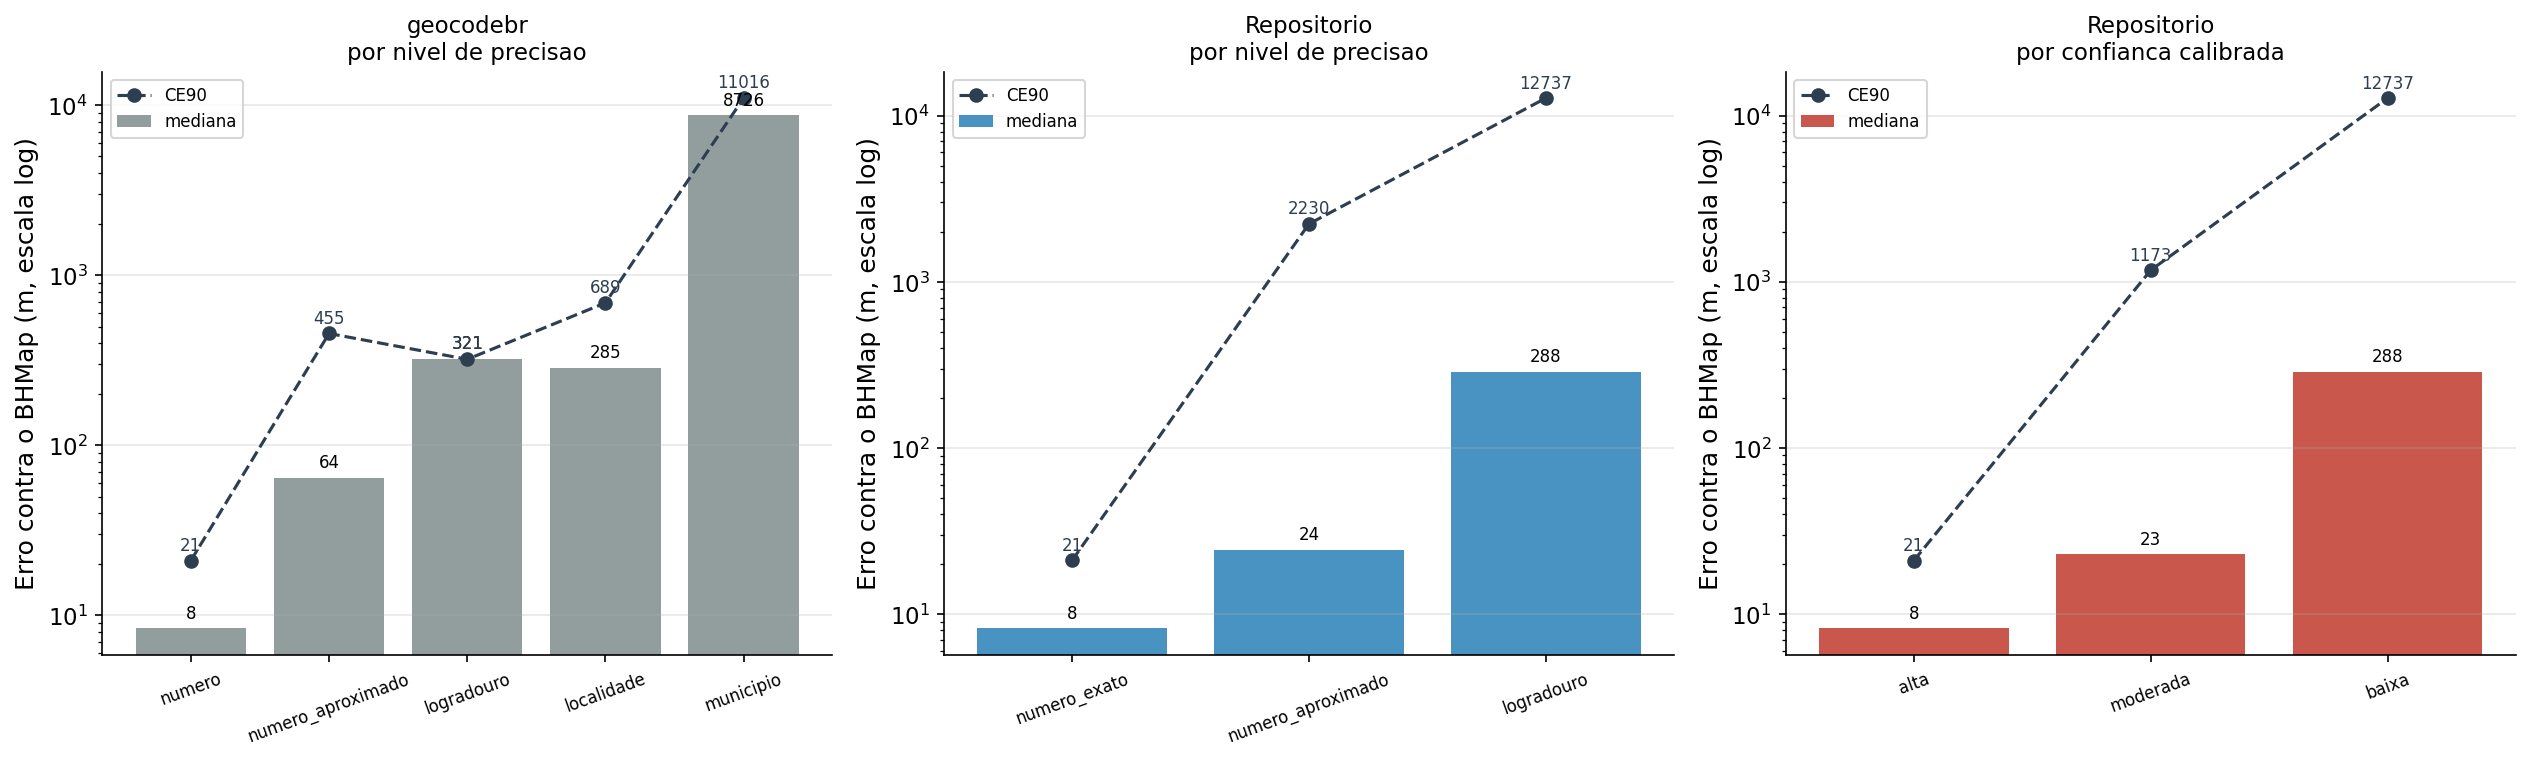

In [15]:
# Figura: o que cada sistema informa sobre o proprio erro
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

def barras_erro(ax, tabela, titulo, cor):
    rotulos = [str(i)[:18] for i in tabela.index]
    ax.bar(rotulos, tabela['Mediana m'], color=cor, alpha=0.85, label='mediana')
    ax.plot(rotulos, tabela['CE90 m'], 'o--', color='#2c3e50', label='CE90')
    for i, (m, c) in enumerate(zip(tabela['Mediana m'], tabela['CE90 m'])):
        ax.text(i, m * 1.15, f'{m:.0f}', ha='center', fontsize=8)
        ax.text(i, c * 1.15, f'{c:.0f}', ha='center', fontsize=8, color='#2c3e50')
    ax.set_yscale('log')
    ax.set_ylabel('Erro contra o BHMap (m, escala log)')
    ax.set_title(titulo, fontsize=11)
    ax.tick_params(axis='x', labelrotation=20, labelsize=8)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis='y')

barras_erro(axes[0], tab_gbr, 'geocodebr\npor nivel de precisao', '#7f8c8d')
barras_erro(axes[1], tab_repo, 'Repositorio\npor nivel de precisao', '#2980b9')
barras_erro(axes[2], tab_conf, 'Repositorio\npor confianca calibrada', '#c0392b')

plt.tight_layout()
plt.savefig(config.FIG_DIR / 'nb14_comparativo_discriminacao.png', dpi=200, bbox_inches='tight')
plt.show()

Os três painéis mostram, em escala logarítmica, o que cada rotulagem promete. As barras são a mediana do erro dentro de cada categoria e a linha é o P90. Uma rotulagem útil produz barras que crescem de forma monotônica e separada. Uma rotulagem inútil produz barras de altura semelhante, porque o rótulo não distingue nada.

### 7.2 O defeito que a operação revelou

Com o limiar mínimo de similaridade padrão do índice de trigrama, que é permissivo, o serviço respondia a consultas cujo logradouro casava mal com o número mais próximo de uma via errada, com aparência de resposta normal. As consultas com similaridade abaixo de 0,9 eram 4,4% do total e concentravam 29% dos erros acima de 100 m, com mediana de 9,3 km nos casamentos mais fracos, e o escalão de número aproximado tinha P90 de 9.726 m. Nenhuma análise dos dados teria exposto isso, porque o defeito estava na política de resposta, e não no dado.

A correção foi calibrada contra o erro medido. Variando o piso de similaridade e o teto de diferença na numeração, exigir similaridade de 0,65 e diferença de até 20 reduz a incidência de erro acima de 100 m de 8,31% para 4,85%, ao custo de 5,4% das respostas, que passam a ser devolvidas no nível de logradouro. Abaixo de 0,45 de similaridade, o serviço recusa a consulta.

| Indicador | Antes | Depois |
|---|---|---|
| AUC da classe de confiança (erro acima de 30 m) | 0,582 | **0,803** |
| AUC do nível de precisão | 0,791 | **0,804** |
| P90 do escalão de número aproximado | 9.726 m | **2.230 m** |
| Erros acima de 100 m no escalão aproximado | 40,2% | **24,5%** |
| Taxa de resposta | 100% | 99,6% |

A classe de confiança passou de quase inútil, com AUC de 0,582, a equivalente ao nível de precisão, e a taxa de resposta caiu meio ponto percentual. Responder a tudo não é virtude quando parte das respostas está a quilômetros do endereço pedido.

## Conclusão

A API está operante e foi submetida a teste. Ela declara a própria cobertura (605.811 endereços, que representam 1.172.902 registros, em um município), devolve coordenada, Plus Code, procedência e nível de precisão, e separa a confiança posicional da incerteza de identidade, com o motivo em texto legível. As rotas respondem em dezenas de milissegundos, e o uso é registrado no banco, por rota e por cliente.

No teste com 20.000 endereços, a classe de confiança separa o erro acima de 30 m com AUC de 0,803, equivalente ao nível de precisão e sem sinal adicional. O índice composto, sozinho, fica em 0,542, e o `geocodebr` discrimina um pouco melhor, com 0,857, por ter mais degraus de degradação anunciados. A operação revelou um defeito de política de resposta que nenhuma análise dos dados mostraria, e a correção por limiares calibrados levou a discriminação da classe de 0,582 a 0,803.

Como produto, o serviço não oferece capacidade que o `geocodebr` não ofereça, e cobre um município. O que ele acrescenta é a separação explícita entre confiança posicional e incerteza de identidade na resposta e a calibração dessa indicação com erro medido. O [NB17](17_teste_operacional_independente.ipynb) testa essa calibração em endereços novos, separados por bloco espacial.